# 04 · Shortcut design and multicomponent distillation

Before a rigorous simulation, a designer wants the size of a column in minutes: the Fenske equation for the
minimum stages, Underwood's for the minimum reflux, Gilliland's correlation for the stages at the chosen
reflux, Kirkbride's for the feed location. The same tools handle multicomponent feeds through the light and
heavy keys. This notebook runs the shortcut, compares it with McCabe-Thiele, optimises the reflux ratio
against cost, and designs a depropaniser.

**What you will learn**
- apply Fenske, Underwood, Gilliland and Kirkbride
- optimise the reflux ratio against cost
- choose keys and estimate non-key distribution for multicomponent feeds
- check a shortcut design for consistency

**Before you start:** notebook 03  ·  **Time:** about 75 min

In [1]:
try:                      # on Google Colab (or anywhere engsep is missing): install it from GitHub
    import engsep
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engsep"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engsep import distillation as dist
from engsep import vle
from engsep.vle import y_from_alpha
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Fenske, Underwood, Gilliland for the benzene-toluene column

In [2]:
alpha = vle.geometric_mean_alpha(("benzene", "toluene"), ideal=True)
xD, xB, zF = 0.95, 0.05, 0.45
sc = dist.fug(alpha, zF, xD, xB, R_over_Rmin=1.3)
print(f"alpha = {alpha:.2f}: N_min = {sc['N_min']:.2f} (Fenske), R_min = {sc['R_min']:.3f} (Underwood), at R = 1.3 R_min = {sc['R']:.2f}: N = {sc['N']:.1f} stages (Gilliland)")
y_eq = lambda x: y_from_alpha(x, alpha)
mt = dist.mccabe_thiele(y_eq, xD, xB, zF, sc["R"])
print(f"McCabe-Thiele at the same reflux: {mt['stages']} stages, feed stage {mt['feed_stage']}")
kb = dist.kirkbride(sc["N"], B=55.0, D=45.0, zF_hk=1 - zF, zF_lk=zF, xB_lk=xB, xD_hk=1 - xD)
print(f"Kirkbride feed stage: {kb['feed_stage_from_top']:.1f} from the top")

alpha = 2.47: N_min = 6.51 (Fenske), R_min = 1.282 (Underwood), at R = 1.3 R_min = 1.67: N = 14.3 stages (Gilliland)
McCabe-Thiele at the same reflux: 14 stages, feed stage 7
Kirkbride feed stage: 7.5 from the top


The shortcut lands within a stage or two of the rigorous count - Gilliland's correlation is an empirical fit
to hundreds of columns, good to perhaps 10-20 % - and Kirkbride puts the feed where McCabe-Thiele does. For a
first estimate, a cost comparison, or a sanity check on a simulator, the three equations are all one needs.

## Reflux ratio versus cost

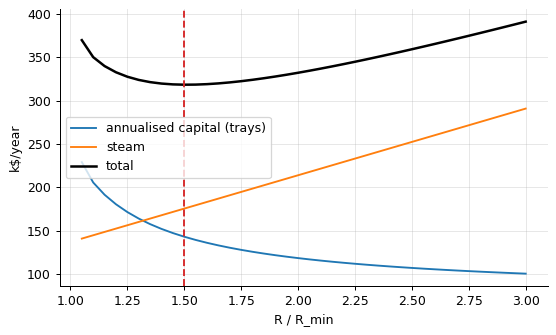

the total cost is minimised at R/R_min = 1.50 (12.5 stages)


In [3]:
RR = np.linspace(1.05, 3.0, 40)
rows = []
for r_ in RR:
    R = r_ * sc["R_min"]
    N = dist.gilliland(R, sc["R_min"], sc["N_min"])
    capital = 80e3 * N / 0.7                                             # $ per real tray (efficiency 0.7), annualised over 10 y below
    D = 45.0                                                             # kmol/h
    steam = (R + 1) * D * 30e3 / 3600 * 8000 * 0.02 / 1e3                # kW of reboiler duty x hours x $/kWh... in k$/y
    rows.append((r_, N, capital / 10 / 1e3, steam, capital / 10 / 1e3 + steam))
rows = np.array(rows)
i = np.argmin(rows[:, 4])
fig, ax = plt.subplots(); ax.plot(rows[:, 0], rows[:, 2], label="annualised capital (trays)"); ax.plot(rows[:, 0], rows[:, 3], label="steam"); ax.plot(rows[:, 0], rows[:, 4], "k", lw=2, label="total"); ax.axvline(rows[i, 0], color="C3", ls="--"); ax.set(xlabel="R / R_min", ylabel="k$/year"); ax.legend(); plt.show()
print(f"the total cost is minimised at R/R_min = {rows[i, 0]:.2f} ({rows[i, 1]:.1f} stages)")

Stages cost capital once; reflux costs steam every hour. The total has a shallow minimum near 1.2-1.5 times
the minimum reflux - the textbook rule of thumb, derived rather than remembered - and the flatness of the
minimum is why the rule is safe: being 20 % off the optimum costs a few percent.

## Multicomponent: keys and non-keys

In [4]:
names = ["propane", "isobutane", "n-butane", "n-pentane"]
z = np.array([0.30, 0.15, 0.35, 0.20])
T_ref = 320.0                                                       # a representative temperature, K
alphas = np.array([vle.antoine_pressure(n, T_ref) for n in names]) / vle.antoine_pressure("n-butane", T_ref)   # relative to the heavy key
print("relative volatilities (to n-butane):", {n: round(float(a), 2) for n, a in zip(names, alphas)})
# depropaniser: light key propane (99 % to the distillate), heavy key n-butane (1 % to the distillate); isobutane distributes, pentane all to the bottoms
d_frac = np.array([0.99, 0.6, 0.01, 0.0])
D_i = z * d_frac; B_i = z - D_i
xD, xB = D_i / D_i.sum(), B_i / B_i.sum()
N_min = dist.fenske(xD[0], xB[0], alphas[0], xD_hk=xD[2], xB_hk=xB[2])
uw = dist.underwood(alphas, z, xD, q=1.0)
R = 1.3 * uw["R_min"]
N = dist.gilliland(R, uw["R_min"], N_min)
print(f"N_min = {N_min:.2f}, R_min = {uw['R_min']:.3f} (Underwood roots {np.round(uw['theta'], 3)}), N = {N:.1f} at R = {R:.2f}")
print(pd.DataFrame({"component": names, "feed": z, "distillate": np.round(xD, 4), "bottoms": np.round(xB, 4)}).to_string(index=False))

relative volatilities (to n-butane): {'propane': 3.44, 'isobutane': 1.38, 'n-butane': 1.0, 'n-pentane': 0.32}
N_min = 7.45, R_min = 2.067 (Underwood roots [0.376 1.212 2.   ]), N = 15.5 at R = 2.69
component  feed  distillate  bottoms
  propane  0.30      0.7606   0.0049
isobutane  0.15      0.2305   0.0984
 n-butane  0.35      0.0090   0.5685
n-pentane  0.20      0.0000   0.3281


With more than two components the designer chooses two adjacent *keys* and specifies their split; the
lighter non-keys go almost entirely overhead, the heavier to the bottoms, and a component between the keys
(isobutane here) distributes. Fenske and Underwood then work as for a binary, with the caveat that the
assumed non-key splits should be checked with Fenske at the end.

## Checking the non-key distribution with Fenske

In [5]:
def fenske_splits(d_frac):
    D_i = z * d_frac; B_i = z - D_i
    xD, xB = D_i / D_i.sum(), B_i / B_i.sum()
    N_min = dist.fenske(xD[0], xB[0], alphas[0], xD_hk=xD[2], xB_hk=xB[2])
    db = (D_i[2] / B_i[2]) * alphas ** N_min                       # (d_i/b_i) = (d_hk/b_hk) alpha_i^N_min at total reflux
    return N_min, db / (1 + db)
for it in range(4):
    N_min, splits = fenske_splits(d_frac)
    print(f"iteration {it}: assumed isobutane split {d_frac[1]:.3f} -> Fenske gives {splits[1]:.3f}  (N_min = {N_min:.2f}; propane {splits[0]:.3f}, pentane {splits[3]:.4f})")
    d_frac = np.array([0.99, splits[1], 0.01, 0.0])
D_i = z * d_frac; B_i = z - D_i
xD, xB = D_i / D_i.sum(), B_i / B_i.sum()
uw = dist.underwood(alphas, z, xD, q=1.0)
print(f"\nconverged design: N_min = {N_min:.2f}, R_min = {uw['R_min']:.3f}, N = {dist.gilliland(1.3 * uw['R_min'], uw['R_min'], N_min):.1f} stages at 1.3 R_min")

iteration 0: assumed isobutane split 0.600 -> Fenske gives 0.098  (N_min = 7.45; propane 0.990, pentane 0.0000)
iteration 1: assumed isobutane split 0.098 -> Fenske gives 0.098  (N_min = 7.45; propane 0.990, pentane 0.0000)
iteration 2: assumed isobutane split 0.098 -> Fenske gives 0.098  (N_min = 7.45; propane 0.990, pentane 0.0000)
iteration 3: assumed isobutane split 0.098 -> Fenske gives 0.098  (N_min = 7.45; propane 0.990, pentane 0.0000)

converged design: N_min = 7.45, R_min = 1.142, N = 16.5 stages at 1.3 R_min


Fenske's equation applies to every component, not just the keys: at total reflux each component's
distillate-to-bottoms ratio scales as $\alpha_i^{N_{min}}$. Propane and pentane split essentially completely,
as assumed - but the isobutane guess of 60 % overhead was wrong: with a volatility only 1.4 times the heavy
key's, it goes 10 % overhead. Replacing the guess converges in one iteration: $N_{min}$ does not change (only
the key ratios enter Fenske), but the distillate is much smaller and lighter than assumed and $R_{min}$ falls
from 2.07 to 1.14. The consistency check is what separates a design from a guess.

## Inside the algorithm: the Fenske equation

In [6]:
print("by hand: N_min =", np.log((xD / (1 - xD)) * ((1 - xB) / xB)) / np.log(alpha) if np.ndim(xD) == 0 else np.log((xD[0] / xD[2]) * (xB[2] / xB[0])) / np.log(alphas[0]), "; library:", N_min)

by hand: N_min = 7.447318844358996 ; library: 7.447318844358996


## Exercises
1. Repeat the depropaniser design with the heavy-key recovery in the distillate at 0.1 % and 5 % instead of 1 %. How do N_min, R_min and the number of stages respond? Which specification is the expensive one?
2. The cost model uses a fixed tray efficiency. Replace it with O'Connell's correlation at three viscosities (0.2, 0.5, 1.0 mPa s) and find how the optimum reflux ratio shifts when trays are less efficient.
3. **Implement it yourself:** write Underwood's equations for a binary (find theta between the two volatilities, then R_min) and compare with the McCabe-Thiele pinch value for benzene-toluene with q = 1.